# Unsupervised Learning — K-Means Clustering and Principal Component Analysis (PCA)

---
Unsupervised learning operates on unlabeled datasets $\{x_1, x_2, \dots, x_n\}$, where $x_i \in \mathbb{R}^d$. Unlike supervised learning, there is no target vector $y$. The objective is to discover underlying structures, groupings, or compressed representations of the input data.

Two main methods of unsupervised learning are:

1. **Clustering (Partitioning):** Grouping data points into distinct, non-overlapping clusters based on similarity (e.g., K-Means).
2. **Dimensionality Reduction (Projection/Compression):** Mapping data from a high-dimensional space $\mathbb{R}^d$ to a lower-dimensional subspace $\mathbb{R}^k$ ($k \ll d$) while retaining critical variance or structure (e.g., PCA).

---

## K-Means Clustering

K-Means partitions $n$ observations into $K$ disjoint clusters $C = \{C_1, C_2, \dots, C_K\}$. Each cluster $C_k$ is represented by its centroid vector $\mu_k \in \mathbb{R}^d$.

The goal is to minimize the **Within-Cluster Sum of Squares (WCSS)**, also referred to as **Inertia** or the distortion cost function $\mathcal{J}$:

$$\mathcal{J}(C, \mu) = \sum_{k=1}^{K} \sum_{i \in C_k} \Vert{}x_i - \mu_k\Vert{}^2$$

where:

* $\Vert{}x_i - \mu_k\Vert{}^2$ is the squared Euclidean distance between observation $x_i$ and centroid $\mu_k$.
* $\mu_k = \frac{1}{\vert{}C_k\vert{}} \sum_{i \in C_k} x_i$ is the mean vector of all points assigned to cluster $C_k$.

---

## Algorithm (Lloyd's method)

The standard K-Means optimization algorithm proceeds iteratively using coordinate descent:

1. **Initialization:** Randomly select $K$ initial cluster centroids $\mu_1, \mu_2, \dots, \mu_K \in \mathbb{R}^d$.
2. **Assignment Step:** Assign each data point $x_i$ to the nearest centroid cluster $C_k^{(t)}$:

$$C_k^{(t)} = \left\{ x_i : \Vert{}x_i - \mu_k^{(t)}\Vert{}^2 \le \Vert{}x_i - \mu_j^{(t)}\Vert{}^2, \, \forall j \in \{1, \dots, K\} \right\}$$


3. **Update Step:** Recalculate each centroid $\mu_k^{(t+1)}$ as the mean of all points assigned to cluster $C_k^{(t)}$:

$$\mu_k^{(t+1)} = \frac{1}{\vert{}C_k^{(t)}\vert{}} \sum_{x_i \in C_k^{(t)}} x_i$$


4. **Convergence Check:** Repeat Steps 2 and 3 until centroids stop changing ($\Vert{}\mu_k^{(t+1)} - \mu_k^{(t)}\Vert{} < \epsilon$) or maximum iterations are reached.

> **Convergence Guarantee:** Lloyd's algorithm is guaranteed to converge to a local minimum because the cost function $\mathcal{J}$ decreases monotonically at every step. However, it is **not** guaranteed to find the global optimum.

---

### Initialization

Standard random initialization can lead to poor local optima. **K-Means++** improves initialization by spreading initial centroids across the feature space:

1. Choose the first centroid $\mu_1$ uniformly at random from the data points.
2. For each data point $x_i$, compute $D(x_i)$, the distance to the nearest already chosen centroid.
3. Choose the next centroid $\mu_k$ randomly from the data points with probability proportional to $D(x_i)^2$:

$$P(x_i) = \frac{D(x_i)^2}{\sum_{j=1}^{n} D(x_j)^2}$$


4. Repeat Steps 2 and 3 until $K$ centroids are chosen.

---

### Optimal Number of Clusters ($K$)

#### 1. The Elbow Method

Plot WCSS (Inertia) against a range of $K$ values. As $K$ increases, WCSS decreases monotonically toward $0$ (when $K=n$, $\text{WCSS}=0$). Select $K$ at the "elbow point" where the rate of decrease drastically slows down.

#### 2. Silhouette Coefficient

For a data point $i$:

* Let $a(i)$ be the mean distance between point $i$ and all other points in the same cluster.
* Let $b(i)$ be the mean distance between point $i$ and all points in the nearest neighboring cluster.

The Silhouette Score $s(i)$ is:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}, \quad s(i) \in [-1, 1]$$

* $s(i) \approx +1$: Point is well-clustered.
* $s(i) \approx 0$: Point lies on the boundary between two clusters.
* $s(i) \approx -1$: Point is misclustered.

Select $K$ that maximizes the mean Silhouette Score across all samples.

---

### Numerical Example

Consider 1D data points: $X = \{2, 4, 10, 12, 30, 32\}$ with $K = 2$.

**Initialization:** Set $\mu_1 = 2$, $\mu_2 = 10$.

* **Iteration 1 — Assignment:**
* Distances to $\mu_1=2$ and $\mu_2=10$:
* $x=2$: $d(2,2)=0, d(2,10)=8 \implies C_1$
* $x=4$: $d(4,2)=2, d(4,10)=6 \implies C_1$
* $x=10$: $d(10,2)=8, d(10,10)=0 \implies C_2$
* $x=12$: $d(12,2)=10, d(12,10)=2 \implies C_2$
* $x=30$: $d(30,2)=28, d(30,10)=20 \implies C_2$
* $x=32$: $d(32,2)=30, d(32,10)=22 \implies C_2$


* $C_1 = \{2, 4\}$, $C_2 = \{10, 12, 30, 32\}$


* **Iteration 1 — Update Centroids:**
* $\mu_1 = \frac{2 + 4}{2} = 3.0$
* $\mu_2 = \frac{10 + 12 + 30 + 32}{4} = \frac{84}{4} = 21.0$


* **Iteration 2 — Assignment:**
* $x=2$: closer to $\mu_1=3 \implies C_1$
* $x=4$: closer to $\mu_1=3 \implies C_1$
* $x=10$: $d(10,3)=7, d(10,21)=11 \implies C_1$
* $x=12$: $d(12,3)=9, d(12,21)=9 \implies C_1 \text{ (or } C_2 \text{)}$
* $x=30$: closer to $\mu_2=21 \implies C_2$
* $x=32$: closer to $\mu_2=21 \implies C_2$
* New clusters: $C_1 = \{2, 4, 10\}$, $C_2 = \{12, 30, 32\}$


* **Iteration 2 — Update Centroids:**
* $\mu_1 = \frac{2 + 4 + 10}{3} = 5.33$
* $\mu_2 = \frac{12 + 30 + 32}{3} = 24.67$



Assignments stabilize after the next iteration, completing convergence.



### Implementation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Generate Synthetic Data
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=0.9, random_state=42)

# 2. Evaluate K using Silhouette Analysis and Inertia
inertia = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

# 3. Fit Final Model with Optimal K=4
final_kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)
cluster_labels = final_kmeans.fit_predict(X)
centroids = final_kmeans.cluster_centers_

print("Final Centroids:\n", centroids)
print(f"Final WCSS (Inertia): {final_kmeans.inertia_:.2f}")

Final Centroids:
 [[ 4.71362999  1.92878701]
 [-8.69721653  7.44225918]
 [-6.98883113 -6.90202274]
 [-2.59291363  9.08462016]]
Final WCSS (Inertia): 768.60


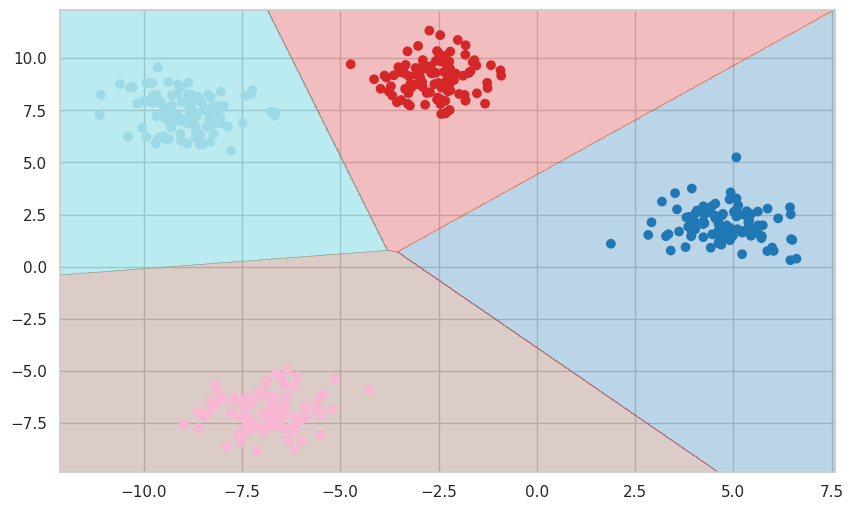

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris, make_blobs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set aesthetic styling
sns.set_theme(style="whitegrid")

# =====================================================================
# Scenario 1: Visualizing 2D Data Clusters with Decision Boundaries
# =====================================================================
# 1. Generate synthetic 2D data
X_2d, _ = make_blobs(
    n_samples=400, centers=4, cluster_std=0.85, random_state=42
)

# 2. Fit K-Means
kmeans_2d = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
labels_2d = kmeans_2d.fit_predict(X_2d)
centroids_2d = kmeans_2d.cluster_centers_

# 3. Create a mesh grid for decision boundaries
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02)
)

# Predict cluster for each point on the grid
Z = kmeans_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. Plot results
plt.figure(figsize=(10, 6))

# Background decision regions
plt.contourf(xx, yy, Z, alpha=0.3, cmap="tab10")

# Data points colored by cluster assignment
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=labels_2d,
    cmap="tab20"
)

---

## Principal Component Analysis (PCA)

PCA is an unsupervised linear dimensionality reduction technique. Given $d$-dimensional features, PCA constructs $k$ new orthogonal variables called **Principal Components** ($k \le d$) that capture the maximum amount of variance in the data.

PCA can be interpreted in two equivalent ways:

1. **Maximizing Variance:** Find directions (orthonormal vectors) onto which the variance of projected data is maximized.
2. **Minimizing Reconstruction Error:** Find a lower-dimensional linear subspace that minimizes the squared distances between original points and their projections.

---

### Variance Maximization

Let $X \in \mathbb{R}^{n \times d}$ be a data matrix with $n$ samples and $d$ features.

#### Step 1: Mean Center the Data

Subtract the sample mean vector $\bar{x} \in \mathbb{R}^d$ from each row of $X$:

$$\tilde{X} = X - \mathbf{1}\bar{x}^T$$

where $\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$.

#### Step 2: Compute the Sample Covariance Matrix

The sample covariance matrix $S \in \mathbb{R}^{d \times d}$ is:

$$S = \frac{1}{n-1} \tilde{X}^T \tilde{X}$$

#### Step 3: Maximize Variance along First Component Direction

We search for a unit vector $u_1 \in \mathbb{R}^d$ ($u_1^T u_1 = 1$) such that the variance of the projected points $\tilde{X} u_1$ is maximized.

The sample variance of projected points is:

$$\text{Var}(\tilde{X} u_1) = \frac{1}{n-1} (\tilde{X} u_1)^T (\tilde{X} u_1) = u_1^T \left( \frac{1}{n-1} \tilde{X}^T \tilde{X} \right) u_1 = u_1^T S u_1$$

Formulate the constrained optimization problem using Lagrange Multipliers:

$$\mathcal{L}(u_1, \lambda_1) = u_1^T S u_1 - \lambda_1 (u_1^T u_1 - 1)$$

Take the derivative with respect to $u_1$ and set to zero:

$$\frac{\partial \mathcal{L}}{\partial u_1} = 2 S u_1 - 2 \lambda_1 u_1 = 0 \implies S u_1 = \lambda_1 u_1$$

> **Result:** $u_1$ must be an **eigenvector** of the covariance matrix $S$, and $\lambda_1$ is its corresponding **eigenvalue**.

The variance along direction $u_1$ is:

$$\text{Var}(\tilde{X} u_1) = u_1^T S u_1 = u_1^T (\lambda_1 u_1) = \lambda_1 (u_1^T u_1) = \lambda_1$$

To maximize variance, $u_1$ must be the eigenvector corresponding to the **largest eigenvalue** $\lambda_1$.

Subsequent principal components $(u_2, u_3, \dots, u_k)$ correspond to eigenvectors of the next largest eigenvalues $(\lambda_2 \ge \lambda_3 \ge \dots \ge \lambda_k)$, subject to the orthogonality constraint $u_j^T u_i = 0$ for $i \neq j$.

---

### Connection to Singular Value Decomposition (SVD)

Rather than computing $S = \frac{1}{n-1}\tilde{X}^T\tilde{X}$ explicitly, modern numerical libraries compute PCA via **Singular Value Decomposition (SVD)** of centered matrix $\tilde{X}$:

$$\tilde{X} = U \Sigma V^T$$

where:

* $U \in \mathbb{R}^{n \times n}$ is an orthogonal matrix of left singular vectors.
* $\Sigma \in \mathbb{R}^{n \times d}$ contains non-negative singular values $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_d$.
* $V \in \mathbb{R}^{d \times d}$ is an orthogonal matrix of right singular vectors (which are precisely the eigenvectors of $S$).

The relationship between eigenvalues of $S$ and singular values $\sigma_i$ is:

$$\lambda_i = \frac{\sigma_i^2}{n - 1}$$

---

### Selecting the Number of Components ($k$)

The total variance present in the dataset is the sum of all eigenvalues $\sum_{j=1}^{d} \lambda_j$.

#### Explained Variance Ratio (EVR)

The proportion of total variance explained by the $j$-th principal component is:

$$\text{EVR}_j = \frac{\lambda_j}{\sum_{m=1}^{d} \lambda_m}$$

The cumulative explained variance for $k$ components is:

$$\text{Cumulative EVR}_k = \frac{\sum_{j=1}^{k} \lambda_j}{\sum_{m=1}^{d} \lambda_m}$$

A standard rule of thumb is selecting $k$ such that the cumulative explained variance reaches a threshold (e.g., $90\%$ or $95\%$).

---

### Example

Consider a 2D dataset ($n=3, d=2$):

$$X = \begin{bmatrix} 2 & 4 \\ 4 & 2 \\ 6 & 6 \end{bmatrix}$$

#### Step 1: Mean Center

Means: $\bar{x}_1 = \frac{2+4+6}{3} = 4$, $\bar{x}_2 = \frac{4+2+6}{3} = 4$.

$$\tilde{X} = \begin{bmatrix} 2-4 & 4-4 \\ 4-4 & 2-4 \\ 6-4 & 6-4 \end{bmatrix} = \begin{bmatrix} -2 & 0 \\ 0 & -2 \\ 2 & 2 \end{bmatrix}$$

#### Step 2: Sample Covariance Matrix

$$S = \frac{1}{3-1} \tilde{X}^T \tilde{X} = \frac{1}{2} \begin{bmatrix} -2 & 0 & 2 \\ 0 & -2 & 2 \end{bmatrix} \begin{bmatrix} -2 & 0 \\ 0 & -2 \\ 2 & 2 \end{bmatrix}$$

$$\tilde{X}^T \tilde{X} = \begin{bmatrix} (-2)^2 + 0^2 + 2^2 & (-2)(0) + (0)(-2) + (2)(2) \\ (-2)(0) + (0)(-2) + (2)(2) & 0^2 + (-2)^2 + 2^2 \end{bmatrix} = \begin{bmatrix} 8 & 4 \\ 4 & 8 \end{bmatrix}$$

$$S = \frac{1}{2} \begin{bmatrix} 8 & 4 \\ 4 & 8 \end{bmatrix} = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix}$$

#### Step 3: Eigenvalues and Eigenvectors

Solve characteristic equation $\vert{}S - \lambda I\vert{} = 0$:

$$\det \begin{bmatrix} 4-\lambda & 2 \\ 2 & 4-\lambda \end{bmatrix} = (4-\lambda)^2 - 4 = 0$$

$$(4-\lambda)^2 = 4 \implies 4-\lambda = \pm 2 \implies \lambda_1 = 6, \quad \lambda_2 = 2$$

* For $\lambda_1 = 6$:

$$\begin{bmatrix} 4-6 & 2 \\ 2 & 4-6 \end{bmatrix} \begin{bmatrix} v_1 \\ v_2 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \end{bmatrix} \implies -2v_1 + 2v_2 = 0 \implies v_1 = v_2$$



Normalized eigenvector $u_1 = \begin{bmatrix} \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \end{bmatrix} \approx \begin{bmatrix} 0.707 \\ 0.707 \end{bmatrix}$
* Explained Variance of First Component:

$$\text{EVR}_1 = \frac{\lambda_1}{\lambda_1 + \lambda_2} = \frac{6}{6 + 2} = \frac{6}{8} = 75\%$$



#### Projection onto 1D Subspace

$$Z = \tilde{X} u_1 = \begin{bmatrix} -2 & 0 \\ 0 & -2 \\ 2 & 2 \end{bmatrix} \begin{bmatrix} \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \end{bmatrix} = \begin{bmatrix} -\sqrt{2} \\ -\sqrt{2} \\ 2\sqrt{2} \end{bmatrix} \approx \begin{bmatrix} -1.414 \\ -1.414 \\ 2.828 \end{bmatrix}$$

---



### Implementation:

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Setup Sample Data
X = np.array([[2, 4], [4, 2], [6, 6]], dtype=float)

# --- Manual PCA via NumPy ---
# A. Mean centering
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean

# B. Covariance matrix
cov_matrix = np.cov(X_centered, rowvar=False)

# C. Eigen-decomposition
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# D. Sort eigenvalues and eigenvectors descending
sort_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_indices]
eigenvectors = eigenvectors[:, sort_indices]

# E. Project centered data onto top principal component
u1 = eigenvectors[:, 0]
Z_manual = X_centered.dot(u1)

print("--- Manual PCA ---")
print("Eigenvalues:", eigenvalues)
print("Top Eigenvector (PC1):", u1)
print("Projected 1D Data:\n", Z_manual)

# --- Scikit-Learn PCA ---
# Note: PCA in sklearn auto-centers data but does not divide by std unless specified
pca = PCA(n_components=1)
Z_sklearn = pca.fit_transform(X)

print("\n--- Scikit-Learn PCA ---")
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Components (PC1):", pca.components_[0])
print("Projected 1D Data:\n", Z_sklearn.ravel())

--- Manual PCA ---
Eigenvalues: [6. 2.]
Top Eigenvector (PC1): [0.70710678 0.70710678]
Projected 1D Data:
 [-1.41421356 -1.41421356  2.82842712]

--- Scikit-Learn PCA ---
Explained Variance Ratio: [0.75]
Components (PC1): [0.70710678 0.70710678]
Projected 1D Data:
 [-1.41421356 -1.41421356  2.82842712]


---

## Comparing K-Means and PCA

| Feature | K-Means Clustering | Principal Component Analysis (PCA) |
| --- | --- | --- |
| **Primary Goal** | Discrete partitioning of samples into $K$ distinct groups | Linear mapping of $d$ features onto $k$ orthogonal axes |
| **Output Type** | Discrete cluster assignments ($y_i \in \{1, \dots, K\}$) | Continuous reduced coordinates ($z_i \in \mathbb{R}^k$) |
| **Feature Scaling** | **Critical:** Sensitive to feature magnitudes (uses Euclidean distance) | **Critical:** Features with higher variance dominate eigenvectors |
| **Optimization Goal** | Minimize intra-cluster variance (WCSS) | Maximize projected data variance |
| **Linearity** | Forms linear Voronoi decision boundaries | Learns linear projections/hyperplanes |
| **Computational Complexity** | $O(I \cdot n \cdot K \cdot d)$ ($I$ iterations) | $O(d^3 + d^2 n)$ via Covariance, $O(n d^2)$ via SVD |

---

## Integrating PCA and K-Means in Practice

Combining PCA and K-Means is a standard workflow for high-dimensional clustering:

1. **Dimensionality Reduction:** High-dimensional space ($d > 50$) suffers from the **Curse of Dimensionality**, causing Euclidean distances to become uniform and less discriminative. Running PCA first compresses features down to $k$ components while retaining the main variance.
2. **Noise Reduction:** Truncating minor principal components removes random noise before cluster boundaries are computed.
3. **Cluster Optimization:** K-Means runs significantly faster and achieves more robust cluster partitions in the reduced feature space $\mathbb{R}^k$.

## Visualising PCA outcome

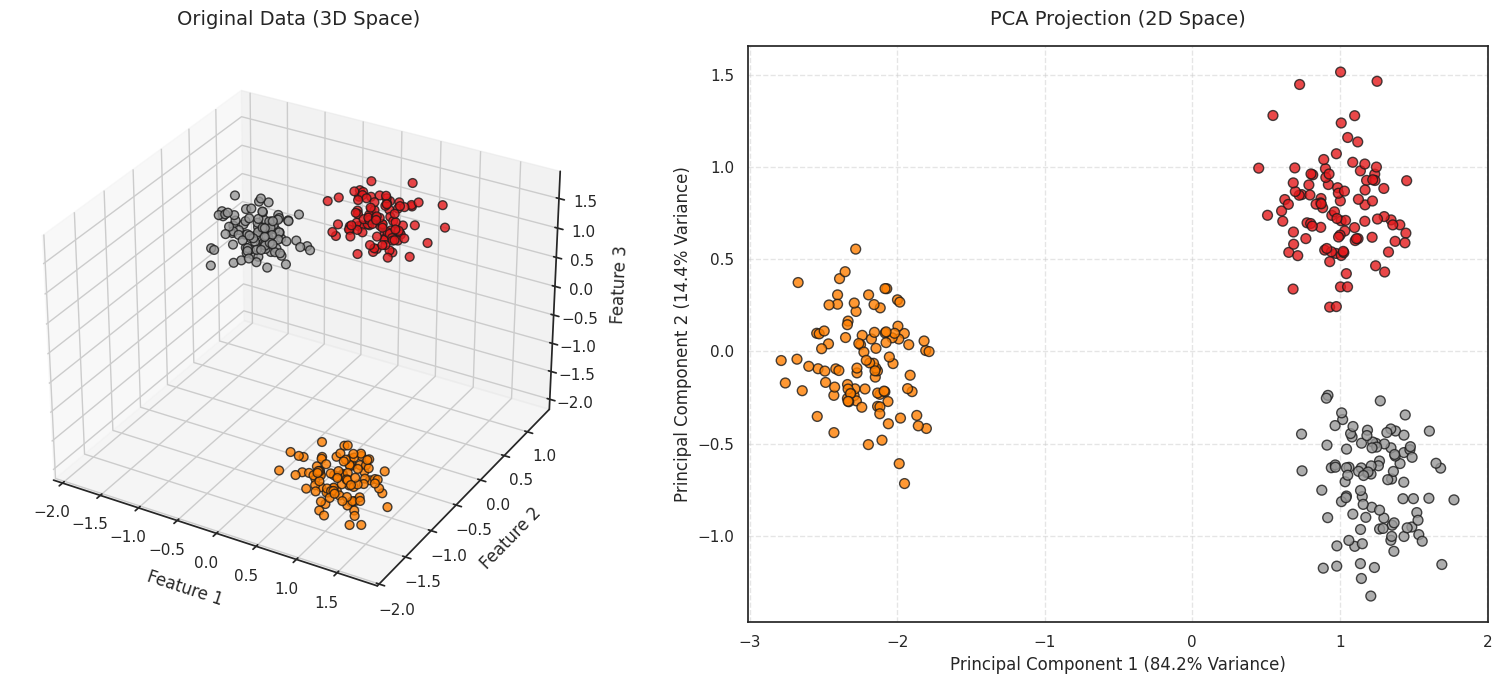

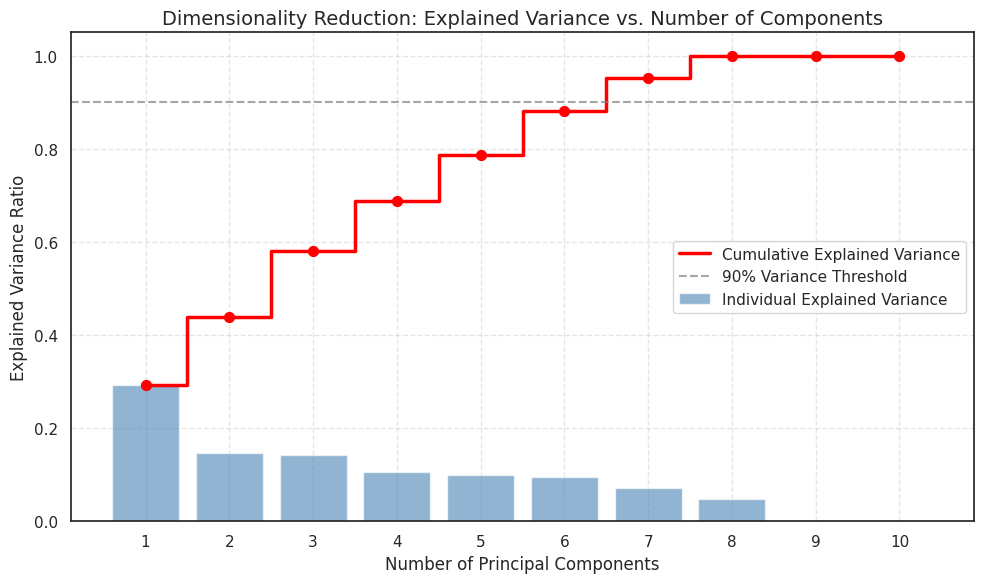

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.datasets import make_blobs, make_classification
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set plot styling
sns.set_theme(style="white")

# =====================================================================
# Demonstration 1: Spatial Reduction from 3D to 2D
# =====================================================================

# 1. Generate synthetic 3D data with 3 clusters
X_3d, y_3d = make_blobs(
    n_samples=300, n_features=3, centers=3, cluster_std=1.2, random_state=42
)

# 2. Standardize features
scaler = StandardScaler()
X_3d_scaled = scaler.fit_transform(X_3d)

# 3. Apply PCA to reduce from 3D to 2D
pca_2d = PCA(n_components=2)
X_2d_proj = pca_2d.fit_transform(X_3d_scaled)

# 4. Create Side-by-Side Plots
fig = plt.figure(figsize=(16, 7))

# Subplot 1: Original 3D Feature Space
ax1 = fig.add_subplot(121, projection="3d")
scatter1 = ax1.scatter(
    X_3d_scaled[:, 0],
    X_3d_scaled[:, 1],
    X_3d_scaled[:, 2],
    c=y_3d,
    cmap="Set1",
    s=40,
    edgecolor="k",
    alpha=0.8,
)
ax1.set_title("Original Data (3D Space)", fontsize=14, pad=15)
ax1.set_xlabel("Feature 1", labelpad=8)
ax1.set_ylabel("Feature 2", labelpad=8)
ax1.set_zlabel("Feature 3", labelpad=8)

# Subplot 2: Projected 2D Principal Component Space
ax2 = fig.add_subplot(122)
scatter2 = ax2.scatter(
    X_2d_proj[:, 0],
    X_2d_proj[:, 1],
    c=y_3d,
    cmap="Set1",
    s=50,
    edgecolor="k",
    alpha=0.8,
)

var_pc1 = pca_2d.explained_variance_ratio_[0] * 100
var_pc2 = pca_2d.explained_variance_ratio_[1] * 100

ax2.set_title("PCA Projection (2D Space)", fontsize=14, pad=15)
ax2.set_xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance)", fontsize=12)
ax2.set_ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance)", fontsize=12)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# =====================================================================
# Demonstration 2: Cumulative Explained Variance Plot (Scree Plot)
# =====================================================================

# 1. Generate synthetic 10-dimensional data
X_10d, _ = make_classification(
    n_samples=500, n_features=10, n_informative=5, random_state=42
)
X_10d_scaled = StandardScaler().fit_transform(X_10d)

# 2. Fit PCA across all 10 components
pca_full = PCA(n_components=10)
pca_full.fit(X_10d_scaled)

exp_variance = pca_full.explained_variance_ratio_
cum_variance = np.cumsum(exp_variance)
components = np.arange(1, 11)

# 3. Plot Scree & Cumulative Variance
fig, ax = plt.subplots(figsize=(10, 6))

# Individual Variance (Bar chart)
ax.bar(
    components,
    exp_variance,
    alpha=0.6,
    color="steelblue",
    label="Individual Explained Variance",
)

# Cumulative Variance (Line plot)
ax.step(
    components,
    cum_variance,
    where="mid",
    color="red",
    linewidth=2.5,
    label="Cumulative Explained Variance",
)
ax.scatter(components, cum_variance, color="red", s=50, zorder=5)

# Highlight 90% variance threshold
ax.axhline(
    y=0.90, color="grey", linestyle="--", alpha=0.7, label="90% Variance Threshold"
)

ax.set_title(
    "Dimensionality Reduction: Explained Variance vs. Number of Components",
    fontsize=14,
)
ax.set_xlabel("Number of Principal Components", fontsize=12)
ax.set_ylabel("Explained Variance Ratio", fontsize=12)
ax.set_xticks(components)
ax.set_ylim(0, 1.05)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="center right", fontsize=11)

plt.tight_layout()
plt.show()